# Kunz et al. 2025, inner speech in motor cortex: decoding the seven cued words

Decodes which of the **seven cued words** (ban, choice, day, feel, kite, though, were) a trial held, separately for each of the seven verbal behaviors of the `isolatedVerbalBehaviors` task: attempted and mimed speech, three kinds of inner speech, passive listening and silent reading. Chance is 1/7.

- **Input**: threshold crossings and spike-band power over the first second of each `Word`, read through `NeuralFeatureExtractor` and averaged over time, one vector per trial.
- **Target**: the word index, read from the `Word` row by `LabelEncoder`.
- **Model**: a linear classifier in plain PyTorch (multinomial logistic regression), with its weight decay chosen on a validation block.
- **Data**: participant T12, the only one with three or more blocks of every behavior. That allows a **block-grouped** split: whole blocks go to training, validation or test, so no test trial shares a recording block with a training trial. The test block is scored once.

**Scope.** This tutorial decodes isolated words. It does not reproduce the paper's headline result, the real-time decoding of self-paced imagined sentences from a 125,000-word vocabulary, which needs a sequence model and a language model.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import confusion_matrix
from torch import nn

import neuralset as ns
import neuralshed.events  # noqa: F401, registers the custom event types
from neuralshed.extractors import NeuralFeatureExtractor
from neuralshed.datasets.kunz_2025 import study, utils
from neuralshed.datasets.utils import dataset_dir
from neuralset.events.etypes import Event
from neuralset.extractors import LabelEncoder

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("kunz_2025") / "data"
s = study.Kunz2025InnerSpeech(path=root)
s.download()

SUBJECT = "T12"
FS = 50.0  # T12's isolated file has 20 ms bins
WINDOW_S = 1.0  # from the start of the Word, shorter than any Word row
WORDS = list(utils.WORDS)
CHANCE = 1 / len(WORDS)
WEIGHT_DECAYS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]  # L2 penalty on the classifier weights
EPOCHS = 500
LEARNING_RATE = 1e-2
REGIMES = ["train-only", "block-adapted"]

BEHAVIORS = [
    "attempted",
    "mimed",
    "imagined_motor",
    "imagined_auditory",
    "imagined_listening",
    "listening",
    "reading",
]
GROUP_COLORS = {
    "attempted": "tab:blue",
    "mimed": "tab:blue",
    "imagined_motor": "tab:orange",
    "imagined_auditory": "tab:orange",
    "imagined_listening": "tab:orange",
    "listening": "tab:green",
    "reading": "tab:green",
}

# extractor disk cache
CACHE = dict(folder=dataset_dir("kunz_2025") / "cache", keep_in_ram=False)


def neural_extractors():
    # threshold crossings in Hz and spike-band power in uV^2, at T12's bin rate
    return {
        "tx": NeuralFeatureExtractor(
            target_unit="Hz",
            event_types=("SpikeCounts",),
            frequency=FS,
            infra=CACHE,
        ),
        "sbp": NeuralFeatureExtractor(
            target_unit="native",
            event_types=("BandPower",),
            frequency=FS,
            infra=CACHE,
        ),
    }


def block_means(events):
    # time-averaged features of every whole block, a label-free statistic of that block
    neural = events[events.type.isin(["SpikeCounts", "BandPower"])]
    means = {}
    for block, rows in neural.groupby("block"):
        row_events = [Event.from_dict(row.to_dict()) for _, row in rows.iterrows()]
        start = float(rows.start.iloc[0])
        duration = float(rows.duration.iloc[0])
        parts = []
        for extractor in neural_extractors().values():
            values = extractor(row_events, start=start, duration=duration).numpy()
            parts.append(values.mean(axis=1))
        means[int(block)] = np.concatenate(parts)
    return means


def fit_linear(features, targets, weight_decay):
    # z-score fit on these trials, then a linear layer trained with cross-entropy
    torch.manual_seed(0)
    mean = features.mean(axis=0)
    std = features.std(axis=0) + 1e-6
    x = torch.tensor((features - mean) / std, dtype=torch.float32)
    y = torch.tensor(targets, dtype=torch.long)

    model = nn.Linear(features.shape[1], len(WORDS))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        loss = loss_fn(model(x), y) + weight_decay * model.weight.pow(2).sum()
        loss.backward()
        optimizer.step()

    def predict(new_features):
        z = torch.tensor((new_features - mean) / std, dtype=torch.float32)
        with torch.no_grad():
            return model(z).argmax(dim=1).numpy()

    return predict


def fit_behavior(features, targets, split):
    # choose the weight decay on the validation block, refit on train + validation, score the test block once
    train = split == "train"
    val = split == "val"
    test = split == "test"

    val_scores = []
    for weight_decay in WEIGHT_DECAYS:
        predict = fit_linear(features[train], targets[train], weight_decay)
        val_scores.append(float((predict(features[val]) == targets[val]).mean()))
    best = WEIGHT_DECAYS[int(np.argmax(val_scores))]

    predict = fit_linear(features[train | val], targets[train | val], best)
    predicted = predict(features[test])
    return {
        "weight_decay": best,
        "val_accuracy": max(val_scores),
        "test_accuracy": float((predicted == targets[test]).mean()),
        "n_test": int(test.sum()),
        "predicted": predicted,
        "true": targets[test],
    }

## 1. One window per word trial

The query keeps T12's `isolatedVerbalBehaviors` blocks. A `Segmenter` triggered on the `Word` rows reads three extractors over the first second of each word: the two neural streams and the word index. In the active blocks the `Word` spans the go period. In the passive listening and reading blocks it spans the presentation of the word. The rest trials are `Action` rows, so they are not triggered.

In [2]:
query = f"experiment == 'isolatedVerbalBehaviors' and subject == 'Kunz2025InnerSpeech/{SUBJECT}'"
events = study.Kunz2025InnerSpeech(path=root, query=query).run()
events = events[events.valid]

words = events[events.type == "Word"]
print(
    "blocks:",
    events.timeline.nunique(),
    "| word trials:",
    len(words),
    "| shortest Word:",
    round(float(words.duration.min()), 2),
    "s",
)

segmenter = ns.dataloader.Segmenter(
    extractors={
        **neural_extractors(),
        "target": LabelEncoder(
            event_types="Word",
            event_field="text",
            predefined_mapping={word: k for k, word in enumerate(WORDS)},
            aggregation="trigger",
        ),
    },
    trigger_query="type == 'Word'",
    start=0.0,
    duration=WINDOW_S,
)
dataset = segmenter.apply(events)
dataset.prepare()
batch = dataset.load_all()

tx = batch.data["tx"].float().numpy()
sbp = batch.data["sbp"].float().numpy()
targets = batch.data["target"].ravel().numpy()
print("tx:", tx.shape, "| sbp:", sbp.shape, "| target:", targets.shape)

trials = pd.DataFrame(
    {
        "behavior": [segment.trigger.extra["behavior"] for segment in batch.segments],
        "block": [int(segment.trigger.extra["block"]) for segment in batch.segments],
        "word": [segment.trigger.text for segment in batch.segments],
    }
)

blocks: 24 | word trials: 1176 | shortest Word: 1.5 s


tx: (1176, 128, 50) | sbp: (1176, 128, 50) | target: (1176,)


## 2. A block-grouped split

Within each behavior the blocks are taken in recording order: the **last block is the test set**, the one before it is the validation set and the earlier ones are the training set. Trials of one block never appear on two sides.

In [3]:
trials["split"] = ""
for behavior in BEHAVIORS:
    rows = trials.behavior == behavior
    blocks = sorted(trials.loc[rows, "block"].unique())
    trials.loc[rows, "split"] = "train"
    trials.loc[rows & (trials.block == blocks[-2]), "split"] = "val"
    trials.loc[rows & (trials.block == blocks[-1]), "split"] = "test"

summary = trials.groupby(["behavior", "split"]).agg(
    blocks=("block", lambda x: sorted(set(x))),
    n_trials=("block", "size"),
)
summary.unstack("split").reindex(BEHAVIORS)

blocks               n_trials          
split                test   train   val     test train val
behavior                                                  
attempted            [26]    [10]  [18]       49    49  49
mimed                [24]     [7]  [16]       49    49  49
imagined_motor       [25]  [8, 9]  [17]       49    98  49
imagined_auditory    [21]  [2, 3]  [13]       49    98  49
imagined_listening   [23]  [5, 6]  [15]       49    98  49
listening            [22]     [4]  [14]       49    49  49
reading              [20]     [1]  [12]       49    49  49

## 3. Features and normalization

Each window is averaged over time, which gives 256 features per trial (128 channels in two streams). Every model below z-scores its inputs with statistics of its own training trials only. The features enter in two versions:

- **train-only**: as read. Nothing about a validation or test block is known before it is decoded.
- **block-adapted**: each block's own mean is subtracted first, the time average of both streams over the whole recorded block. The authors subtract block-wise means before decoding, because the baseline drifts between blocks. The statistic uses no labels, but it needs the test block's neural recording, so it assumes a decoder that may watch a new block before scoring it (as the authors' rolling z-scoring does online).

In [4]:
pooled = np.concatenate([tx.mean(axis=2), sbp.mean(axis=2)], axis=1)
means = block_means(events)
offsets = np.stack([means[block] for block in trials.block])

versions = {
    "train-only": pooled,
    "block-adapted": pooled - offsets,
}
print("features:", pooled.shape, "| blocks with a mean:", len(means))

features: (1176, 256) | blocks with a mean: 24


## 4. Fit one decoder per behavior

For each behavior and each version of the features, a linear layer is trained with cross-entropy and an L2 penalty (full batch, Adam, a fixed seed). The penalty is chosen on the validation block, the model is refit on the training and validation blocks together, and the test block is scored once.

In [5]:
results = {regime: {} for regime in REGIMES}
for regime in REGIMES:
    for behavior in BEHAVIORS:
        rows = (trials.behavior == behavior).to_numpy()
        results[regime][behavior] = fit_behavior(
            versions[regime][rows],
            targets[rows],
            trials.loc[rows, "split"].to_numpy(),
        )

scores = pd.concat(
    {
        regime: pd.DataFrame(results[regime]).T[
            ["weight_decay", "val_accuracy", "test_accuracy", "n_test"]
        ]
        for regime in REGIMES
    },
    axis=1,
).astype(float)
table = scores.round(3)
for regime in REGIMES:
    weight_decay = scores[(regime, "weight_decay")]
    table[(regime, "weight_decay")] = weight_decay.map("{:g}".format)
print(f"chance: {CHANCE:.3f}")
table

chance: 0.143


train-only                                   block-adapted                                  
                   weight_decay val_accuracy test_accuracy n_test  weight_decay val_accuracy test_accuracy n_test
attempted                  0.01        0.776         0.918   49.0         0.001        0.878         0.898   49.0
mimed                      0.01        0.714         0.694   49.0           0.1        0.735         0.776   49.0
imagined_motor           0.0001        0.469         0.408   49.0             1        0.653         0.551   49.0
imagined_auditory          0.01        0.347         0.551   49.0           0.1        0.633         0.633   49.0
imagined_listening            1        0.469         0.592   49.0         0.001        0.531         0.531   49.0
listening                  0.01        0.367         0.306   49.0          0.01        0.408         0.347   49.0
reading                       1        0.367         0.429   49.0         0.001        0.327         0.490   49.0

## 5. Test accuracy per behavior

Accuracy on the held-out test block of each behavior, for both versions of the features, with the binomial standard error of 49 trials.

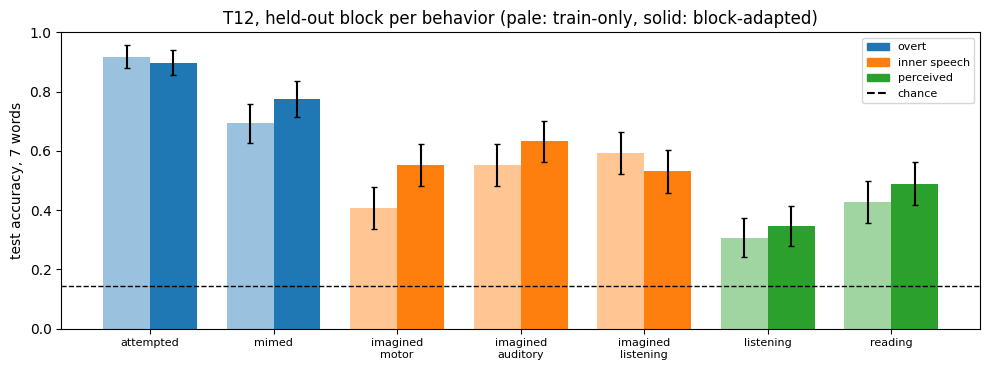

In [6]:
labels = [b.replace("_", "\n") for b in BEHAVIORS]
positions = np.arange(len(BEHAVIORS))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 3.8))
for k, regime in enumerate(REGIMES):
    accuracy = scores[(regime, "test_accuracy")][BEHAVIORS]
    n_test = scores[(regime, "n_test")][BEHAVIORS]
    error = np.sqrt(accuracy * (1 - accuracy) / n_test)
    ax.bar(
        positions + (k - 0.5) * width,
        accuracy,
        width=width,
        yerr=error,
        color=[GROUP_COLORS[b] for b in BEHAVIORS],
        alpha=0.45 if regime == "train-only" else 1.0,
        capsize=2,
    )
ax.axhline(CHANCE, color="k", ls="--", lw=1)
ax.set(
    xticks=positions,
    ylabel="test accuracy, 7 words",
    ylim=(0, 1),
    title=f"{SUBJECT}, held-out block per behavior (pale: train-only, solid: block-adapted)",
)
ax.set_xticklabels(labels, fontsize=8)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=c)
    for c in ("tab:blue", "tab:orange", "tab:green")
]
handles.append(plt.Line2D([0], [0], color="k", ls="--"))
ax.legend(
    handles,
    ["overt", "inner speech", "perceived", "chance"],
    fontsize=8,
    loc="upper right",
)
plt.tight_layout()
plt.show()

The confusion matrix of the attempted-speech test block, train-only features.

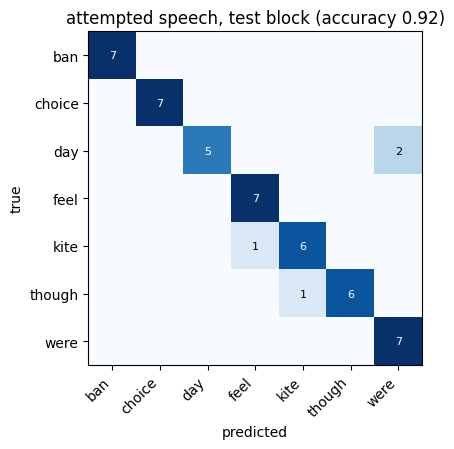

In [7]:
attempted = results["train-only"]["attempted"]
confusion = confusion_matrix(
    attempted["true"],
    attempted["predicted"],
    labels=range(len(WORDS)),
)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.imshow(confusion, cmap="Blues")
ax.set(
    xticks=range(len(WORDS)),
    yticks=range(len(WORDS)),
    xticklabels=WORDS,
    yticklabels=WORDS,
    xlabel="predicted",
    ylabel="true",
)
ax.set_title(
    f"attempted speech, test block (accuracy {attempted['test_accuracy']:.2f})"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(len(WORDS)):
    for j in range(len(WORDS)):
        if confusion[i, j]:
            color = "white" if confusion[i, j] > confusion.max() / 2 else "black"
            ax.text(
                j,
                i,
                confusion[i, j],
                ha="center",
                va="center",
                color=color,
                fontsize=8,
            )
plt.tight_layout()
plt.show()

## Notes

- The headline is the **attempted-speech test accuracy, 0.92** with train-only normalization (45 of 49 trials, chance 0.14), and 0.90 block-adapted. Mimed speech reaches 0.69 and 0.78, the three inner-speech behaviors 0.41-0.59 and 0.53-0.63, silent reading 0.43 and 0.49, passive listening 0.31 and 0.35. Every behavior is above chance in both versions, and the order follows the paper's gradient from overt to inner to perceived speech.
- Block adaptation raises five of the seven behaviors, most for motoric inner speech (0.41 to 0.55). It is the choice to make when a decoder can see a block's recording before decoding it. The train-only number is the one for a decoder that cannot.
- Each test set is one block of 49 trials, seven per word, so the standard error is 0.04-0.07. Differences among the three inner-speech behaviors, between listening and reading, or between the two versions of one behavior, are mostly inside that error.
- Random folds over the same trials would put trials of one block on both sides of the split, sharing its baseline, and would overstate what transfers to a new block.
- The weight decay is chosen on a single validation block of 49 trials, which is a noisy criterion. It affects the choice of model only, never the test score.
- The features average the first second of each trial over time and pool both of T12's 6v arrays. The paper decodes from go-aligned windows chosen per array and behavior, so its numbers are not comparable one to one.
- T15, T16 and T17 have two blocks of most behaviors. The same protocol there leaves one training block and no validation block, which is why this example uses T12.